# Módulo 1 · ¿De dónde sale el potencial de acción? (Hodgkin-Huxley)

**Gancho clínico.** Los anestésicos locales, muchos antiepilépticos y la intoxicación por tetrodotoxina actúan sobre la misma molécula: el canal de sodio dependiente de voltaje. Para razonar sobre ellos hace falta una imagen de cómo las corrientes de Na⁺ y K⁺ construyen un disparo.

**El modelo.** La membrana es un condensador en paralelo con tres conductancias:

$$C\,\frac{dV}{dt} = I_{estím} - \bar g_{Na}\,m^3h\,(V-E_{Na}) - \bar g_K\,n^4\,(V-E_K) - g_L\,(V-E_L)$$

y cada compuerta $x\in\{m,h,n\}$ sigue $dx/dt = \alpha_x(V)(1-x) - \beta_x(V)\,x$.

**Al terminar podrás** (1) decir qué ion produce la subida y cuál la repolarización, (2) leer gráficas de compuertas y (3) reconocer la excitabilidad de tipo II en una curva f-I.

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

Lee el simulador junto a la ecuación: cada línea dentro del bucle es un término.

In [2]:
print(inspect.getsource(ns.simulate_hh))

def simulate_hh(stimulus, duration=100.0, dt=0.01, params=None, V0=-65.0, init=None):
    """Simulate one isopotential Hodgkin-Huxley patch.

    Parameters
    ----------
    stimulus : float or callable
        Injected current density (µA/cm²), constant or a function of time.
    duration, dt : float
        Simulated time and integration step (ms).
    params : dict, optional
        Overrides for :data:`SQUID`, e.g. ``{"gNa": 84}`` for a 30 % sodium block.
    V0 : float
        Initial voltage; gates start at their steady state for V0.
    init : dict, optional
        Full initial state ``{"V", "m", "h", "n"}`` (see :func:`settle`).

    Returns
    -------
    dict with arrays ``t, V, m, h, n, I_Na, I_K, I_L``.
    """
    p = dict(SQUID, **(params or {}))
    drive = stimulus if callable(stimulus) else (lambda _t: stimulus)
    n_steps = int(round(duration / dt))
    t = np.arange(n_steps) * dt
    V, m, h, n = (np.empty(n_steps) for _ in range(4))
    if init is None:
       

## 1.1 Un pulso de corriente

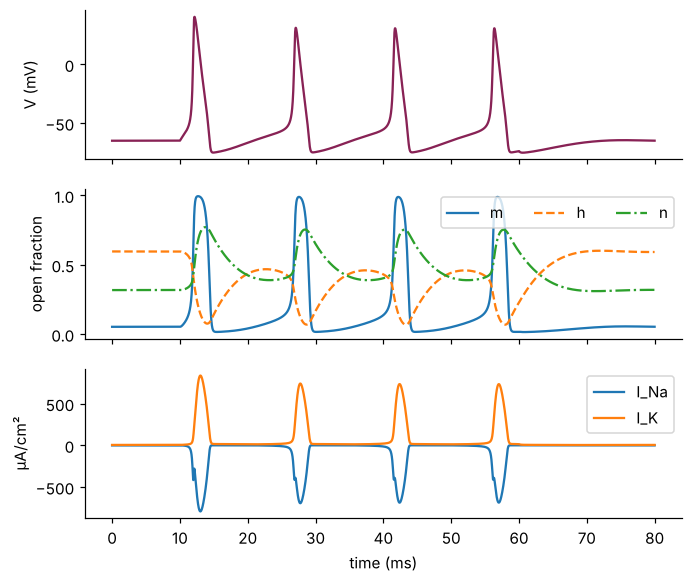

In [3]:
pulse = lambda t: 10.0 if 10 <= t < 60 else 0.0     # µA/cm² between 10 and 60 ms
r = ns.simulate_hh(pulse, duration=80)
fig, ax = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
ax[0].plot(r['t'], r['V'], color='#882255'); ax[0].set_ylabel('V (mV)')
for g, ls in zip('mhn', ['-', '--', '-.']): ax[1].plot(r['t'], r[g], ls, label=g)
ax[1].set_ylabel('open fraction'); ax[1].legend(ncol=3)
ax[2].plot(r['t'], r['I_Na'], label='I_Na'); ax[2].plot(r['t'], r['I_K'], label='I_K')
ax[2].set_ylabel('µA/cm²'); ax[2].set_xlabel('time (ms)'); ax[2].legend(); plt.show()

## 1.2 La curva frecuencia-corriente (f-I)

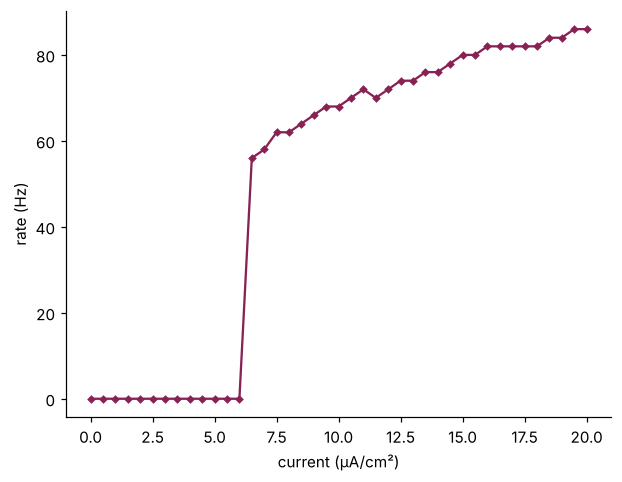

In [4]:
currents = np.arange(0, 20.1, 0.5)
rates = [ns.hh_rate(I) for I in currents]
plt.plot(currents, rates, 'D-', ms=3, color='#882255')
plt.xlabel('current (µA/cm²)'); plt.ylabel('rate (Hz)'); plt.show()

## Ejercicios
1. **TTX.** Bloquea todos los canales de sodio con `params={'gNa': 0}`. ¿Qué le pasa a la respuesta al pulso y por qué?
2. **Potasio.** Reduce `gK` a la mitad. ¿Cómo cambian el ancho del disparo y la frecuencia?
3. **Umbral para un pulso breve.** Encuentra la amplitud mínima de un pulso de 1 ms que produce un disparo (pista: prueba entre 5 y 10 µA/cm²).
4. **Tipo II.** ¿Por qué la curva f-I salta de 0 a unos 50 Hz en lugar de subir suavemente desde 0?
5. **Temperatura (reto).** La cinética de las compuertas se acelera unas tres veces por cada 10 °C (Q10 ≈ 3). Multiplica todas las velocidades por 3 en una copia de `gate_rates` y describe el efecto en la forma del disparo.